# EmPath · Pilot scope explorer

Run all cells with the project `.venv` interpreter. This notebook uses cached public data and displays both maps. It currently screens canopy variation; learned edge weights and pedestrian routing are the next milestone.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "scripts").exists():
    ROOT = ROOT.parent
assert (ROOT / "scripts" / "visualize.py").exists(), "Open the EmPath project folder first"
sys.path.insert(0, str(ROOT / "scripts"))
from screen_pilot_scope import run
summary = run()
summary.round(2)

 zcta  land_area_sqmi  valid_canopy_coverage_pct  overlapping_block_groups  approx_area_weighted_canopy_pct  weighted_p10_canopy_pct  weighted_p90_canopy_pct  min_block_canopy_pct  max_block_canopy_pct
75023            9.20                      100.0                        57                            19.33                    11.24                    26.68                  6.47                 40.30
75024           12.95                      100.0                        60                            16.24                     8.39                    26.08                  0.90                 42.08
75025            9.55                      100.0                        56                            18.54                    12.49                    24.28                  4.59                 43.95
75074           15.98                       98.0                        54                            19.79                     7.56                    31.86                  4.40             

,zcta,land_area_sqmi,valid_canopy_coverage_pct,overlapping_block_groups,approx_area_weighted_canopy_pct,weighted_p10_canopy_pct,weighted_p90_canopy_pct,min_block_canopy_pct,max_block_canopy_pct
0,75023,9.20,100.0,57,19.33,11.24,26.68,6.47,40.30
1,75024,12.95,100.0,60,16.24,8.39,26.08,0.90,42.08
2,75025,9.55,100.0,56,18.54,12.49,24.28,4.59,43.95
3,75074,15.98,98.0,54,19.79,7.56,31.86,4.40,37.82


## Interactive map

Hover over a polygon to inspect its canopy estimate. Toggle ZIP layers on the right. The fixed color scale makes ZIPs comparable. Internet is needed for basemap tiles and browser mapping libraries.

In [2]:
from visualize import build_map
build_map()

## Static map

This image can be viewed without loading online basemap tiles.

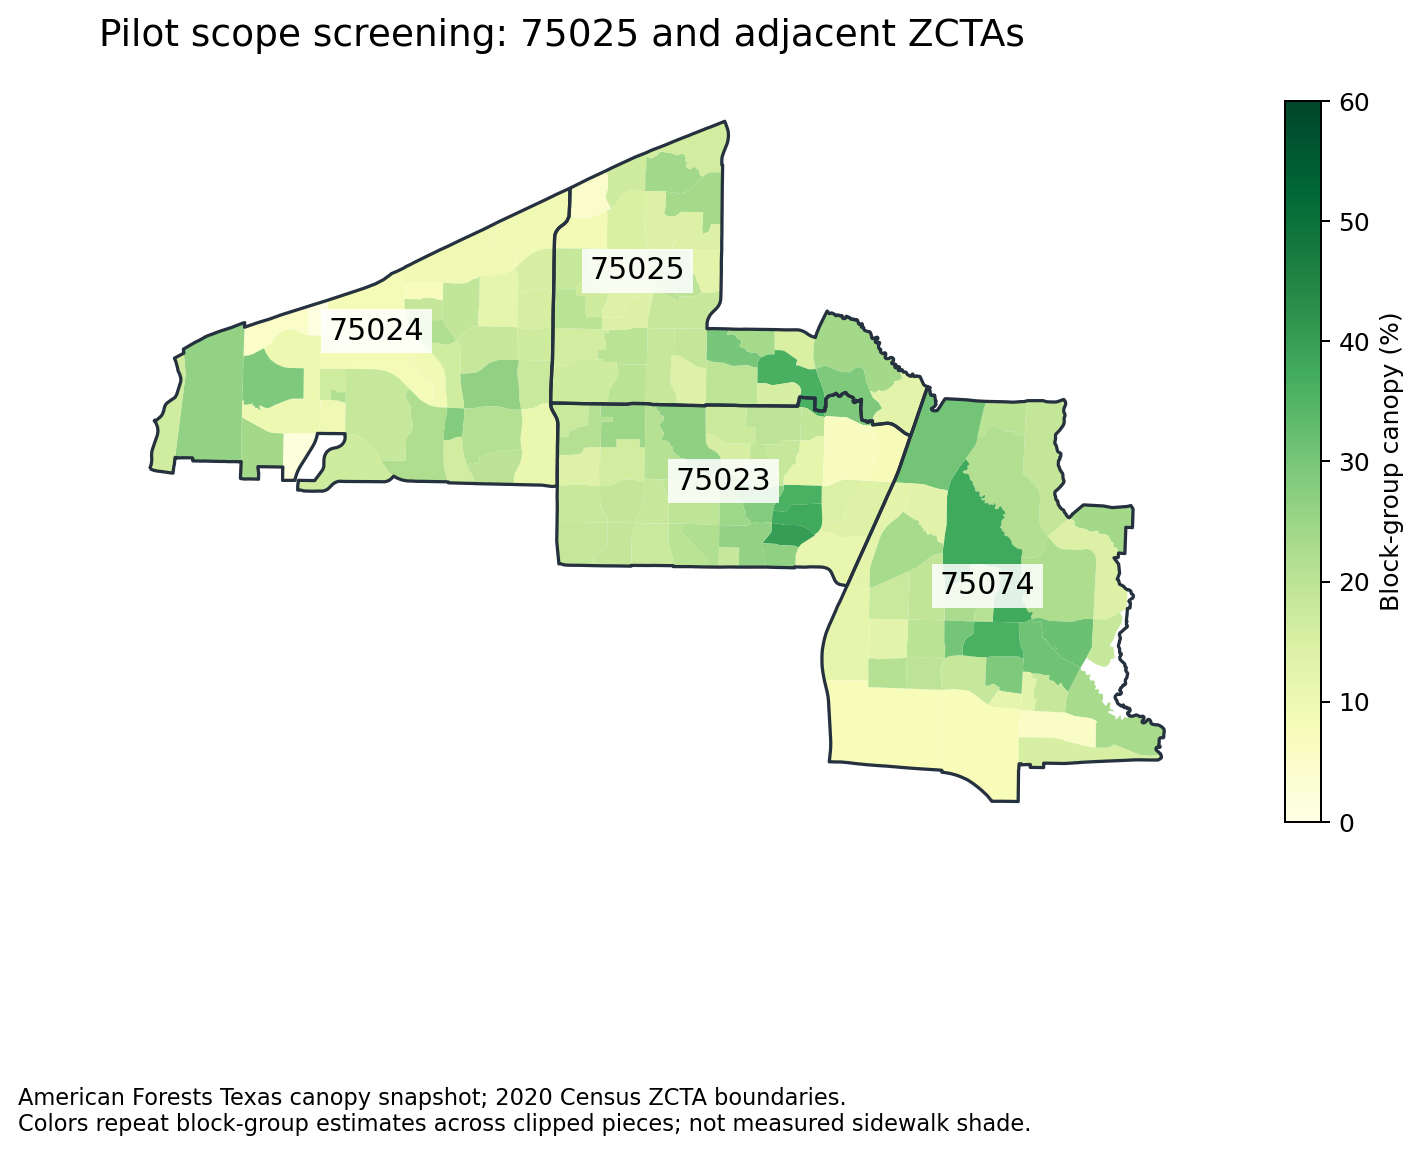

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "output/scope_screen/canopy_screen.png")))

## Data provenance and limits

Canopy is a block-group estimate, not actual shade on each sidewalk. Values are area weighted and assigned uniformly to clipped polygon pieces. The underlying imagery date is unverified. Missing coverage is not zero canopy. No health outcome or trained edge-weight prediction is displayed.

In [4]:
import json
metadata = json.loads((ROOT / "output/scope_screen/source_metadata.json").read_text())
metadata

{'retrieved_utc': '2026-11-07T23:48:32.206210+00:00',
 'canopy_service': 'https://tes-app-data-share.s3.amazonaws.com/tx/tx_geojson.zip',
 'boundary_service': 'https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/tigerWMS_ACS2024/MapServer/2',
 'download_last_modified': 'Tue, 27 Oct 2026 17:34:15 GMT',
 'limitations': ['Official download snapshot; underlying canopy acquisition year unverified.',
  'Block-group canopy values assigned to overlapping ZCTA pieces, not measured within each piece.',
  'Not sidewalk shade, current heat resilience, air temperature, or medical risk.']}